# POD EEG: the complete Alljoined-1.6M scheduled corpus

This companion to [the Alljoined-1 EEG demo](pod_demo_eeg.ipynb) tests the library's
large-data objective on **all 1,520 scheduled continuous recordings** from 20
participants. The float32 signal matrix is **14.18 GiB**, with 32 EEG channels,
256 Hz sampling and about 129 hours of recording. Participants 1–19 learn the
shared channel basis; participant 20 is held out. Every participant is encoded.

The question is how much signal can be reconstructed from a smaller saved
representation while processing input larger than the RAM visible in the reference WSL2 environment.
No stimulus images, labels or decoding model are used.

Source: [authors' Alljoined-1.6M release](https://huggingface.co/datasets/Alljoined/Alljoined-1.6M)
and [paper](https://arxiv.org/abs/2508.18571). See [setup and benchmark instructions](README_neuro.md#complete-alljoined-16m-corpus).
Run `python -m demos.benchmark_eeg_large` from the repository root first.
The required JSON report, signal arrays and encoded factors are generated
locally and stay in ignored files. The notebook's saved outputs show plots
and measurements from a previous reference run.

In [1]:
from __future__ import annotations

import json
import os
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
import dask
import dask.array as da
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import xarray as xr
from IPython.display import Markdown, display

from demos.eeg_analysis import (
    band_power_errors,
    correlation_matrix,
    covariance_scores,
    participant_validation,
)
from demos.eeg_large import (
    CHANNELS,
    PREPROCESSING,
    cache_manifest,
    cached_recording,
    load_encoded_spectra,
    read_h5_block,
    validate_encoding,
)
from svdrom import POD

dask.config.set(scheduler="threads", num_workers=2)
plt.rcParams.update({"figure.dpi": 85})
rank_colors = {8: "tab:blue", 16: "tab:green", 32: "tab:orange"}
cache = Path(
    os.environ.get("SVDROM_EEG_LARGE_CACHE", "data/alljoined16/conditioned.h5")
)
report_path = Path(
    os.environ.get("SVDROM_EEG_LARGE_REPORT", "eeg_large_benchmark.json")
)
encoded_dir = Path(
    os.environ.get("SVDROM_EEG_LARGE_ENCODED", str(cache.parent / "encoded"))
)
report = json.loads(report_path.read_text())
assert report["preprocessing"] == PREPROCESSING
assert "encode" in report, "Run the complete benchmark before opening this notebook."
manifest = cache_manifest(cache)
assert manifest == report["prepare"]["manifest"]
records = manifest["records"]
print("Reference run:", report["completed_at_utc"])
print("Reference platform:", report["platform"])
print("Reference package versions:", report["versions"])
print("Reference environment-visible RAM:", round(report["total_ram_gib"], 2), "GiB")
print("Current visible RAM:", round(psutil.virtual_memory().total / 2**30, 2), "GiB")

Reference run: 2026-10-04T13:54:54.360625+00:00
Reference platform: Linux-6.18.33.2-microsoft-standard-WSL2-x86_64-with-glibc2.39
Reference package versions: {'svdrom': '0.1.0', 'numpy': '2.4.6', 'dask': '2026.7.1', 'xarray': '2026.7.0', 'mne': '1.13.2', 'scipy': '1.18.0', 'h5py': '3.16.0', 'psutil': '7.2.2'}
Reference environment-visible RAM: 7.39 GiB
Current visible RAM: 7.39 GiB


## 1. Audit the actual EEG matrix

The release contains equipment telemetry and annotations alongside the 32
electrodes. Those fields do not count toward the signal matrix. The audit checks
all 20 × 4 × 19 expected paths, EDF header calibration, rate and payload length.
Directory identity resolves participant 8's known filename errors. Other EDF
paths are listed separately; scheduled recordings are counted once. This is a
complete scheduled-path audit, not a cryptographic content-integrity guarantee.

In [2]:
assert len(records) == 1520
assert {r["subject"] for r in records} == set(range(1, 21))
assert all(sum(r["subject"] == s for r in records) == 76 for s in range(1, 21))
n_samples = sum(r["n_samples"] for r in records)
n_train = sum(r["n_samples"] for r in records if r["subject"] != 20)
signal_bytes = 32 * n_samples * 4
print(f"EEG matrix: 32 x {n_samples:,} float32 values = {signal_bytes / 2**30:.2f} GiB")
print(f"Training matrix: {32 * n_train * 4 / 2**30:.2f} GiB")
print(
    "Source EDF files, including telemetry: "
    f"{sum(r['bytes'] for r in records) / 2**30:.2f} GiB"
)
print(f"Recording hours: {n_samples / 256 / 3600:.2f}")
print(
    "Noncanonical EDF paths listed separately:", len(manifest["noncanonical_edf_files"])
)
print(f"Prepared cache on disk: {report['prepare']['cache_bytes'] / 2**30:.2f} GiB")
with h5py.File(cache, "r") as store:
    statistics = [
        {"n_samples": r["n_samples"], "covariance": store[f"{r['key']}/covariance"][:]}
        for r in records
    ]
train_cov = (
    sum(
        s["covariance"] * s["n_samples"]
        for r, s in zip(records, statistics, strict=True)
        if r["subject"] != 20
    )
    / n_train
)
test_samples = n_samples - n_train
test_cov = (
    sum(
        s["covariance"] * s["n_samples"]
        for r, s in zip(records, statistics, strict=True)
        if r["subject"] == 20
    )
    / test_samples
)

EEG matrix: 32 x 118,967,040 float32 values = 14.18 GiB
Training matrix: 13.49 GiB
Source EDF files, including telemetry: 25.13 GiB
Recording hours: 129.09
Noncanonical EDF paths listed separately: 61
Prepared cache on disk: 15.17 GiB


## 2. Prepare on disk, then fit a lazy matrix

Preparation uses a fourth-order 0.5 Hz high-pass in both directions, 32 seconds
of neighboring filter context, and per-record centering. Every EEG sample and
electrode is retained. There is no notch filter, rereferencing, ICA or artifact
rejection. Filtering intentionally discards slow variation, so reconstruction
scores refer to the conditioned signal.

Chunked HDF5 stores channel-by-time arrays; Dask reads only needed blocks.
Parquet can similarly support partial table reads, but format choice alone does
not bound RAM. Here the fit accumulates a **32 × 32 covariance matrix** and keeps
the full-length time coefficients lazy. The time axis remains at its native
length. Small covariance storage is a sufficient statistic for learning modes,
not a replacement for the encoded temporal coefficients. Covariance storage grows quadratically with channel count and its squared condition number reduces accuracy for weak modes. This backend is suitable for this 32-channel, very long time axis; it is not a general memory guarantee for large spatial dimensions.

This cell executes a new full training fit using the public SVD-ROM API. Its
elapsed time belongs to this kernel; the next section shows the separately
measured fresh-process reference benchmark.

In [3]:
train_data = da.concatenate(
    [cached_recording(cache, r, 16_384) for r in records if r["subject"] != 20], axis=1
)
train = xr.DataArray(train_data, dims=("channel", "sample"))
started = time.perf_counter()
pod = POD(
    n_modes=24,
    svd_algorithm="covariance",
    time_dimension="sample",
    remove_mean=False,
    compute_time_coeffs=False,
    compute_energy_ratio=True,
).fit(train)
print(f"Current kernel fit: {time.perf_counter() - started:.1f} s")
print(
    "Lazy input shape:", train.shape, "; lazy coefficient shape:", pod.time_coeffs.shape
)
ranks = (4, 8, 16, 24)
held_out = covariance_scores(test_cov, pod.modes.values, ranks)
training = covariance_scores(train_cov, pod.modes.values, ranks)
display(
    pd.DataFrame(
        {
            "rank": ranks,
            "training_energy": [training[k]["energy"] for k in ranks],
            "held_out_energy": [held_out[k]["energy"] for k in ranks],
            "held_out_rmse_uv": [held_out[k]["rmse"] for k in ranks],
        }
    )
)
for encoding in report["encode"]["encodings"]:
    k = encoding["rank"]
    verified = encoding["verification"]["participants"]["20"]
    np.testing.assert_allclose(
        held_out[k]["energy"], verified["energy_retained"], atol=2e-6
    )

Current kernel fit: 35.5 s
Lazy input shape: (32, 113202432) ; lazy coefficient shape: (24, 113202432)


,rank,training_energy,held_out_energy,held_out_rmse_uv
0,4,0.969637,0.890570,6.599025
1,8,0.985079,0.941479,4.825774
2,16,0.994854,0.980918,2.755684
3,24,0.998243,0.991999,1.784404


## 3. Input size versus memory and elapsed time

Each fit case runs in a new process, using two Dask threads and one BLAS thread.
Preparation and the complete fit/encode/decode/spectral worker have separate
memory measurements. Peak RSS includes each worker's imports and stages, but
excludes this notebook, other processes and filesystem cache. The source cache
is prepared before fit timing. Shared workloads and warm filesystem caches
affect elapsed times; these plots use the locally generated benchmark report,
not current kernel RSS. The dashed line is RAM visible in that benchmark
environment, not independently measured physical laptop RAM. The saved
reference outputs come from WSL2 and show input exceeding its visible RAM.
RSS is not total system memory use, and graph metadata can grow with the
number of input blocks.

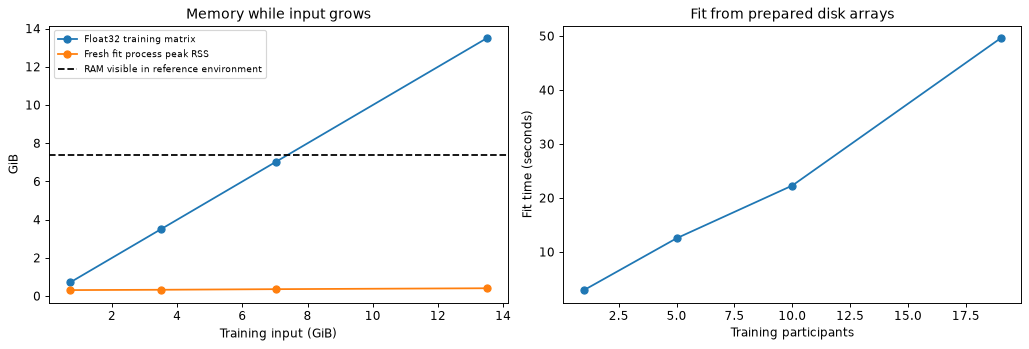

,stage,peak_rss_gib
0,Prepare complete corpus,0.345627
1,Fit + encode + decode + spectra,0.427185


Measured complete preparation: 576.8 s
Encoding / verification seconds: [(8, 116.8, 61.0), (16, 126.0, 64.4)]


In [4]:
cases = report["cases"]
sizes = [c["training_gib"] for c in cases]
peaks = [c["peak_rss_gib"] for c in cases]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(sizes, sizes, "o-", label="Float32 training matrix")
axes[0].plot(sizes, peaks, "o-", label="Fresh fit process peak RSS")
axes[0].axhline(
    report["total_ram_gib"],
    color="black",
    linestyle="--",
    label="RAM visible in reference environment",
)
axes[0].set(
    xlabel="Training input (GiB)", ylabel="GiB", title="Memory while input grows"
)
axes[0].legend(fontsize=8)
axes[1].plot(
    [c["training_participants"] for c in cases], [c["fit_seconds"] for c in cases], "o-"
)
axes[1].set(
    xlabel="Training participants",
    ylabel="Fit time (seconds)",
    title="Fit from prepared disk arrays",
)
plt.show()
display(
    pd.DataFrame(
        {
            "stage": ["Prepare complete corpus", "Fit + encode + decode + spectra"],
            "peak_rss_gib": [
                report["prepare"]["peak_rss_gib"],
                report["encode"]["peak_rss_gib"],
            ],
        }
    )
)
print(f"Measured complete preparation: {report['prepare']['seconds']:.1f} s")
print(
    "Encoding / verification seconds:",
    [
        (
            e["rank"],
            round(e["encoding_seconds"], 1),
            round(e["verification_seconds"], 1),
        )
        for e in report["encode"]["encodings"]
    ],
)

## 4. Real disk storage and full decoded reconstruction

The benchmark projects and writes **every recording** at ranks 8 and 16, then
reopens the files and decodes every sample from the saved float32 factors.
POD normalization is absorbed into coefficients: the disk decoder is simply
`modes @ coefficients`. Adding the saved per-record mean recovers the filtered
level. It cannot undo filtering.

Nominal bytes count coefficients, one shared basis and one mean per recording.
Actual file bytes additionally count HDF5 chunk padding, headers and metadata.
No lossless compression filter is enabled. Ratios below use the original
float32 **EEG matrix** as the baseline; source EDFs have a different numeric
representation and include telemetry. Before plotting, we check each file's manifest, conditioning, training participant IDs, rank and recording dimensions, and compare its saved basis with this kernel's fit. Spectral artifacts additionally identify the actual bases and encoded file sizes. These are provenance checks, not checksums of all coefficients; the benchmark's full decode is the numerical round-trip check.

,rank,payload_gib,file_gib,nominal_ratio,actual_file_ratio,held_out_energy,held_out_rmse_uv,correlation_rmse
0,8,3.545676,3.795475,3.999795,3.736549,0.941479,4.825774,0.174014
1,16,7.091171,7.583562,1.999948,1.870094,0.980918,2.755684,0.061613


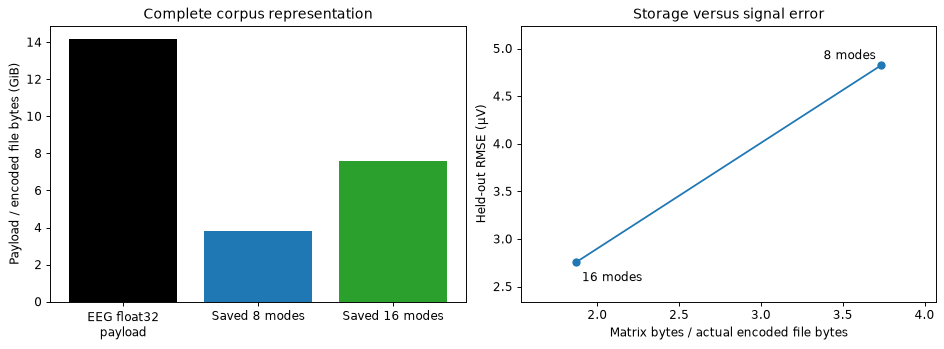

In [5]:
encodings = report["encode"]["encodings"]
rows = []
for e in encodings:
    path = encoded_dir / f"rank{e['rank']:02d}.h5"
    identity = validate_encoding(cache, path, rank=e["rank"])
    assert identity["file_bytes"] == e["file_bytes"]
    with h5py.File(path, "r") as store:
        saved_basis = store["modes"][:].astype("f8")
    fitted_basis = pod.modes.values[:, : e["rank"]]
    np.testing.assert_allclose(
        saved_basis @ saved_basis.T, fitted_basis @ fitted_basis.T, atol=2e-6
    )
    test = e["verification"]["participants"]["20"]
    rows.append(
        {
            "rank": e["rank"],
            "payload_gib": e["payload_bytes"] / 2**30,
            "file_gib": e["file_bytes"] / 2**30,
            "nominal_ratio": e["nominal_compression"],
            "actual_file_ratio": e["file_compression"],
            "held_out_energy": test["energy_retained"],
            "held_out_rmse_uv": test["rmse_uv"],
            "correlation_rmse": test["correlation_rmse"],
        }
    )
storage_table = pd.DataFrame(rows)
display(storage_table)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].bar(
    ["EEG float32\npayload", "Saved 8 modes", "Saved 16 modes"],
    [signal_bytes / 2**30, *storage_table.file_gib.tolist()],
    color=["black", rank_colors[8], rank_colors[16]],
)
axes[0].set(
    ylabel="Payload / encoded file bytes (GiB)", title="Complete corpus representation"
)
axes[1].plot(storage_table.actual_file_ratio, storage_table.held_out_rmse_uv, "o-")
for row in rows:
    axes[1].annotate(
        f"{row['rank']} modes",
        (row["actual_file_ratio"], row["held_out_rmse_uv"]),
        xytext=(-5, 5) if row["rank"] == 8 else (5, -16),
        ha="right" if row["rank"] == 8 else "left",
        textcoords="offset points",
    )
axes[1].margins(x=0.18, y=0.2)
axes[1].set(
    xlabel="Matrix bytes / actual encoded file bytes",
    ylabel="Held-out RMSE (µV)",
    title="Storage versus signal error",
)
plt.show()

## 5. Inspect saved-factor waveforms

This two-second interior window shows three electrodes with the same amplitude
scale for each original/reconstruction comparison. It is an illustrative view;
the numerical errors above use all samples of participant 20's 76 recordings.

The large Fp1 transient near 61 seconds is also reproduced. Preserving that
transient does not establish its physiological origin; artifacts can contribute
to the energy scores.

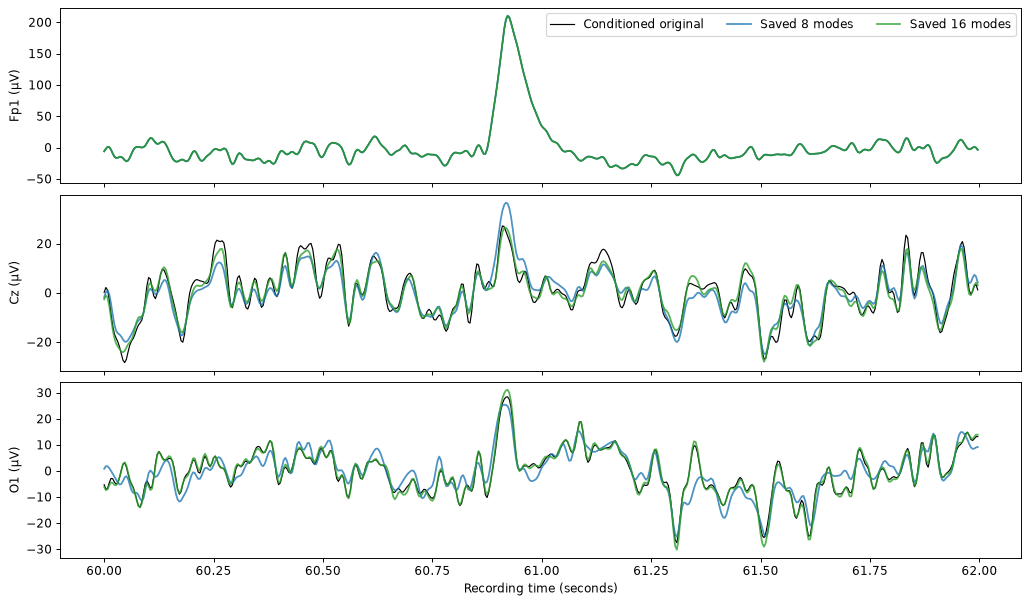

In [6]:
example = next(
    r for r in records if r["subject"] == 20 and r["session"] == 1 and r["block"] == 1
)
start, stop = 60 * 256, 62 * 256
observed = read_h5_block(cache, f"{example['key']}/signal", start, stop)
decoded = {}
for k in (8, 16):
    with h5py.File(encoded_dir / f"rank{k:02d}.h5", "r") as store:
        decoded[k] = (
            store["modes"][:] @ store[f"{example['key']}/coefficients"][:, start:stop]
        )
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
for ax, channel in zip(axes, ("Fp1", "Cz", "O1"), strict=True):
    index = CHANNELS.index(channel)
    ax.plot(
        np.arange(start, stop) / 256,
        observed[index],
        color="black",
        label="Conditioned original",
        linewidth=1,
    )
    for k in (8, 16):
        ax.plot(
            np.arange(start, stop) / 256,
            decoded[k][index],
            label=f"Saved {k} modes",
            color=rank_colors[k],
            alpha=0.8,
        )
    ax.set(ylabel=f"{channel} (µV)")
axes[0].legend(ncol=3)
axes[-1].set_xlabel("Recording time (seconds)")
plt.show()

## 6. Spectral preservation across the full held-out participant

These Welch spectra use **every complete eight-second window** from all 76
held-out recordings, with 50% overlap. No window crosses a recording boundary;
the final incomplete window of each recording is omitted. Summaries are
weighted by window count and combined in a reduction tree. Both reconstructions
come from the actual saved factors. Channel power is in µV²/Hz. Line-noise bands
are included as diagnostics, not interpreted as brain rhythms.

Complete Welch windows: 5523


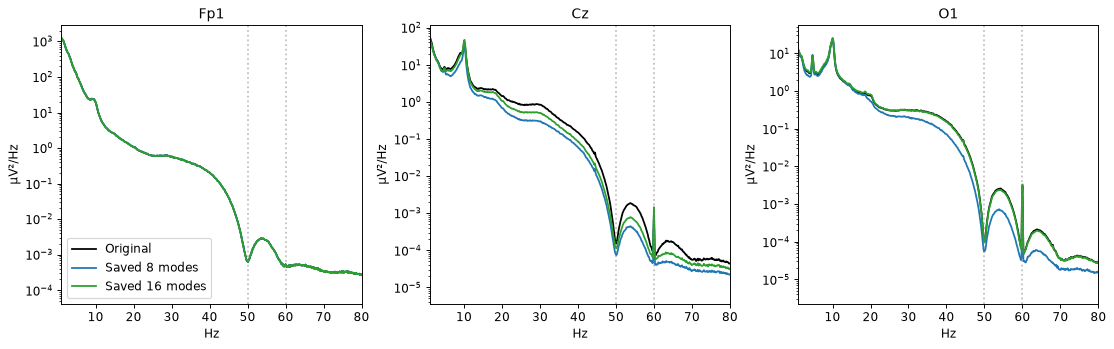

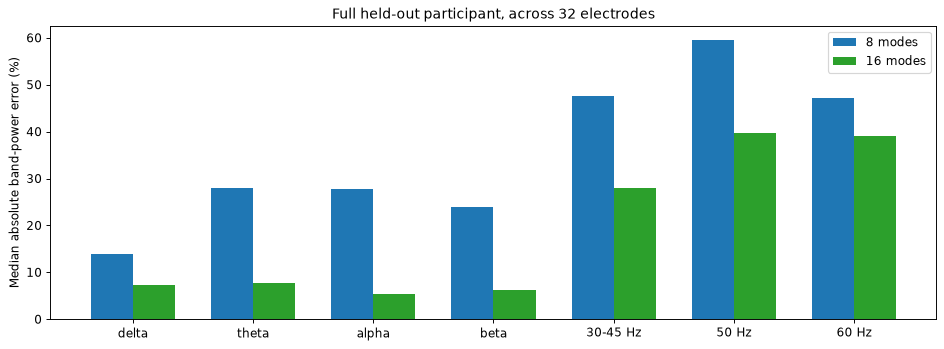

In [7]:
spectral = load_encoded_spectra(
    cache,
    tuple(encoded_dir / f"rank{k:02d}.h5" for k in (8, 16)),
    encoded_dir / "spectra.h5",
)
frequencies, psd = spectral["frequencies"], spectral["psd"]
assert spectral["n_windows"] == report["encode"]["spectra"]["n_windows"]
print("Complete Welch windows:", spectral["n_windows"])
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, channel in zip(axes, ("Fp1", "Cz", "O1"), strict=True):
    index = CHANNELS.index(channel)
    for curve, label, color in zip(
        psd[:, index],
        ("Original", "Saved 8 modes", "Saved 16 modes"),
        ("black", rank_colors[8], rank_colors[16]),
        strict=True,
    ):
        ax.semilogy(frequencies, curve, label=label, color=color)
    ax.set(xlim=(1, 80), xlabel="Hz", ylabel="µV²/Hz", title=channel)
    ax.axvline(50, color="grey", linestyle=":", alpha=0.5)
    ax.axvline(60, color="grey", linestyle=":", alpha=0.5)
axes[0].legend()
plt.show()
bands = {
    "delta": (1, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30),
    "30-45 Hz": (30, 45),
    "50 Hz": (49, 51),
    "60 Hz": (59, 61),
}
band_errors = band_power_errors(frequencies, psd, bands)
medians = np.array(
    [100 * np.nanmedian(np.abs(values), axis=1) for values in band_errors.values()]
)
for name, measured in zip(bands, medians, strict=True):
    reference_name = f"{name} noise" if name in ("50 Hz", "60 Hz") else name
    np.testing.assert_allclose(
        measured,
        report["encode"]["spectra"]["median_absolute_band_power_error_percent"][
            reference_name
        ],
        rtol=1e-5,
        atol=1e-5,
    )
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
for index, k in enumerate((8, 16)):
    ax.bar(
        np.arange(len(bands)) + (index - 0.5) * 0.35,
        medians[:, index],
        width=0.35,
        label=f"{k} modes",
        color=rank_colors[k],
    )
ax.set(
    xticks=np.arange(len(bands)),
    xticklabels=list(bands),
    ylabel="Median absolute band-power error (%)",
    title="Full held-out participant, across 32 electrodes",
)
ax.legend()
plt.show()

## 7. Channel correlations and participant validation

Covariance determines full-recording linear projection error and channel
correlations. The matrices below show analytical projection correlations using
the saved bases. Full decoded correlation errors were separately measured from
the actual files in the storage table. These are descriptive channel statistics,
not physiological source maps or functional-connectivity estimates.

The 20 validation folds exclude **every session/block of one participant** when
learning modes. They reuse the full-recording covariances, reproducing the
covariance fit without 20 more corpus reads. Every participant counts equally
in the summary. This differs from scoring training participants under the shared
participant-20 model. The same conditioning and rank grid are used in every fold. This is exploratory reconstruction validation, developed with access to these data; it is not a blind confirmatory experiment. The current cached-covariance calculations below are checked against the reference report.

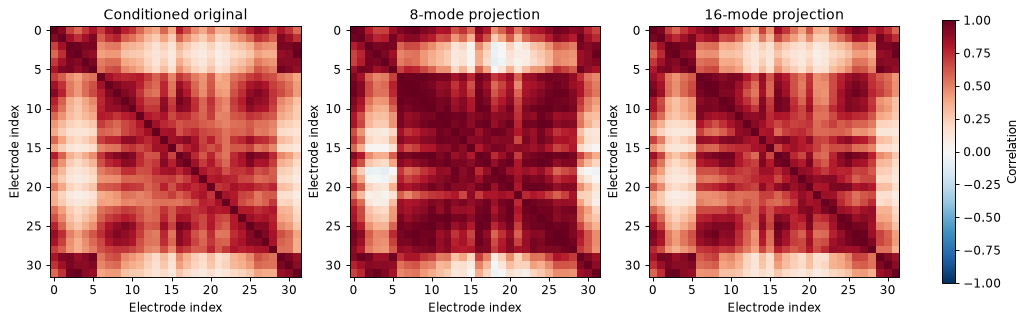

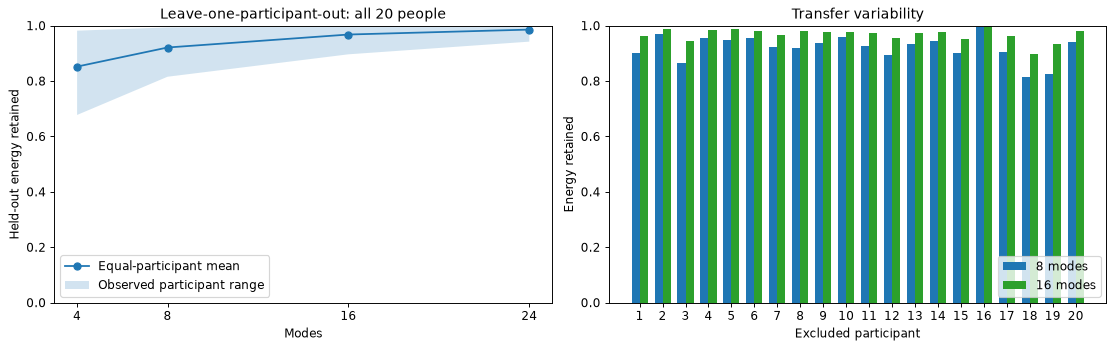

In [8]:
correlations = [correlation_matrix(test_cov)]
for k in (8, 16):
    with h5py.File(encoded_dir / f"rank{k:02d}.h5", "r") as store:
        basis = store["modes"][:].astype("f8")
    projection = basis @ basis.T
    correlations.append(correlation_matrix(projection @ test_cov @ projection.T))
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, corr, title in zip(
    axes,
    correlations,
    ("Conditioned original", "8-mode projection", "16-mode projection"),
    strict=True,
):
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set(title=title, xlabel="Electrode index", ylabel="Electrode index")
fig.colorbar(im, ax=axes, label="Correlation", shrink=0.8)
plt.show()
folds = participant_validation(statistics, [r["subject"] for r in records], ranks)
reference_folds = report["encode"]["participant_folds"]
assert [f["subject"] for f in folds] == [f["subject"] for f in reference_folds]
for fold, reference in zip(folds, reference_folds, strict=True):
    for k in ranks:
        np.testing.assert_allclose(
            fold["ranks"][k]["test_energy"],
            reference["ranks"][str(k)]["test_energy"],
            atol=2e-6,
        )
fold_energy = np.array(
    [[fold["ranks"][k]["test_energy"] for k in ranks] for fold in folds]
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
axes[0].plot(ranks, fold_energy.mean(axis=0), "o-", label="Equal-participant mean")
axes[0].fill_between(
    ranks,
    fold_energy.min(axis=0),
    fold_energy.max(axis=0),
    alpha=0.2,
    label="Observed participant range",
)
axes[0].set(
    xlabel="Modes",
    xticks=ranks,
    ylabel="Held-out energy retained",
    ylim=(0, 1),
    title="Leave-one-participant-out: all 20 people",
)
axes[0].legend()
for index, k in enumerate((8, 16)):
    axes[1].bar(
        np.arange(1, 21) + (index - 0.5) * 0.35,
        fold_energy[:, ranks.index(k)],
        width=0.35,
        label=f"{k} modes",
        color=rank_colors[k],
    )
axes[1].set(
    xlabel="Excluded participant",
    ylabel="Energy retained",
    ylim=(0, 1),
    xticks=np.arange(1, 21),
    title="Transfer variability",
)
axes[1].legend(loc="lower right")
plt.show()

## 8. Inspect channel quality before interpreting modes

This audit flags each participant's most imbalanced recording by the largest
electrode contribution to its conditioned variance. Records remain in the
analysis. Dominance may reflect electrode/reference problems or artifacts and
does not identify a physiological source. High training energy alone is
insufficient evidence of useful neural compression.

,subject,record,channel,variance_share,std_uv
0,1,sub01_s01_b11,Fp1,0.672221,112.805188
1,2,sub02_s04_b08,Fp1,0.423901,100.515806
2,3,sub03_s04_b19,Fp2,0.671414,93.054611
3,4,sub04_s03_b03,Fp2,0.765677,152.038551
4,5,sub05_s03_b09,Fp1,0.663126,137.132346
5,6,sub06_s01_b09,Fp1,0.408894,73.640858
6,7,sub07_s03_b10,Fp2,0.646087,165.719254
7,8,sub08_s01_b18,Fp2,0.589112,194.926357
8,9,sub09_s04_b10,Fp1,0.577860,146.816589
9,10,sub10_s04_b16,F5,0.433952,103.984780


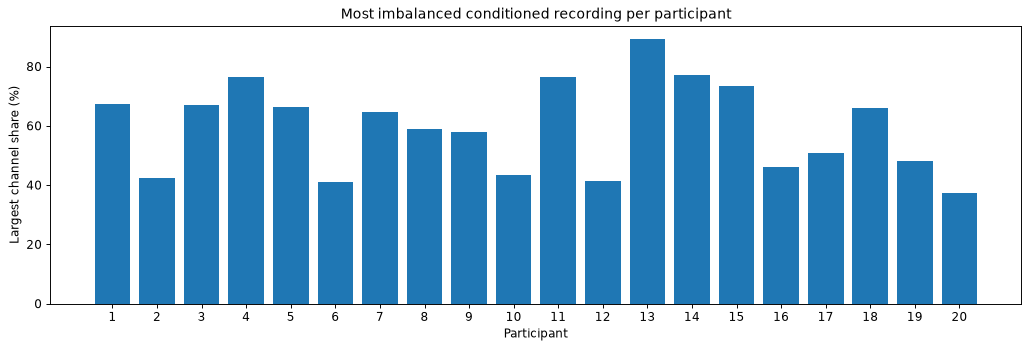

In [9]:
quality = []
for subject in range(1, 21):
    candidates = []
    for r, stat in zip(records, statistics, strict=True):
        if r["subject"] != subject:
            continue
        variances = np.diag(stat["covariance"])
        index = int(np.argmax(variances))
        candidates.append(
            {
                "subject": subject,
                "record": r["key"],
                "channel": CHANNELS[index],
                "variance_share": variances[index] / variances.sum(),
                "std_uv": np.sqrt(variances[index]),
            }
        )
    quality.append(max(candidates, key=lambda item: item["variance_share"]))
display(pd.DataFrame(quality))
fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.bar([q["subject"] for q in quality], [100 * q["variance_share"] for q in quality])
ax.set(
    xlabel="Participant",
    ylabel="Largest channel share (%)",
    xticks=np.arange(1, 21),
    title="Most imbalanced conditioned recording per participant",
)
plt.show()

## What this adds to the existing demos

- Like ERA5 SVD, it saves a smaller representation and reconstructs the signal.
- Like airfoil POD, it measures fluctuation energy and frequency structure.
- Like weather DMD evaluation, it uses a stated baseline and exposes scientific
  limitations alongside computational performance. No forecasting is claimed.
- It adds actual encoded file sizes, complete disk round-trip verification,
  full-participant spectral checks and participant transfer validation.

The smaller EEG notebook remains the detailed 64-electrode acquisition example;
this 32-electrode corpus supplies the stronger large-data demonstration.
Compression quality remains a measured trade-off. Additional recordings alone
do not guarantee stronger compression or physiological validity.

In [10]:
full = next(c for c in cases if c["training_participants"] == 19)
display(
    Markdown(
        f"The **{full['training_gib']:.2f} GiB training matrix** was fitted with "
        f"**{full['peak_rss_gib']:.2f} GiB fresh-process peak RSS**, versus "
        f"**{report['total_ram_gib']:.2f} GiB RAM visible "
        "in the benchmark environment**. "
        "The complete "
        "encoding/verification worker peaked at "
        f"**{report['encode']['peak_rss_gib']:.2f} GiB**. "
        "Compare the training matrix size with the benchmark's visible RAM; "
        "the saved WSL2 reference run exceeded it. Laptops with more physical "
        "RAM may still hold this input. "
        "The reference report does not identify physical laptop RAM. "
        "Saved-factor reconstruction, spectra and "
        "participant variability quantify what each compression rank preserves. "
        "The target is conditioned EEG, and acquisition-aware signal validation "
        "remains necessary for physiological interpretation."
    )
)

The **13.49 GiB training matrix** was fitted with **0.41 GiB fresh-process peak RSS**, versus **7.39 GiB RAM visible inside WSL2**. The complete encoding/verification worker peaked at **0.43 GiB**. This demonstrates input exceeding the reference environment RAM; laptops with more physical RAM may still hold this input. The reference report does not identify physical laptop RAM. Saved-factor reconstruction, spectra and participant variability quantify what each compression rank preserves. The target is conditioned EEG, and acquisition-aware signal validation remains necessary for physiological interpretation.